In [1]:
print("Importing...")
import sys
%load_ext autoreload
%autoreload 2
sys.path.insert(
    0,
    "/glade/u/home/manishrv/documents/nwa12_0.1/regional_mom_workflows/CrocoDash/CrocoDash/rm6",
)
import regional_mom6 as rm6
from regional_mom6.utils import ap2ep, ep2ap
import xarray as xr
import os
import pandas as pd
from pathlib import Path
import numpy as np



Importing...


In [2]:
hgrid = xr.open_dataset(
    "/glade/u/home/manishrv/documents/nwa12_0.1/mom_input/2n3b.nwa-three-boundary-new-regridding/hgrid.nc"
)
hgrid

<xarray.Dataset> Size: 111MB
Dimensions:   (nyp: 1561, nxp: 1481, ny: 1560, nx: 1480)
Dimensions without coordinates: nyp, nxp, ny, nx
Data variables:
    tile      |S255 255B ...
    y         (nyp, nxp) float64 18MB ...
    x         (nyp, nxp) float64 18MB ...
    dy        (ny, nxp) float64 18MB ...
    dx        (nyp, nx) float64 18MB ...
    area      (ny, nx) float64 18MB ...
    angle_dx  (nyp, nxp) float64 18MB ...
Attributes:
    file_name:    ocean_hgrid.nc
    Description:  MOM6 NCAR NWA12
    Author:       Fred Castruccio (fredc@ucar.edu)
    Created:      2024-04-18T08:39:49.607481
    type:         MOM6 supergrid file

In [56]:
pseudo_hgrid_x = np.full((len(hgrid.nyp) + 2, len(hgrid.nxp)+2), np.nan)
pseudo_hgrid_y = np.full((len(hgrid.nyp) + 2, len(hgrid.nxp)+2), np.nan)

pseudo_hgrid_x[1:-1, 1:-1] = hgrid.x.values
pseudo_hgrid_x[0, 1:-1] = hgrid.x.values[0,:] - (hgrid.x.values[1,:] - hgrid.x.values[0,:]) # Bottom Fill
pseudo_hgrid_x[-1, 1:-1] = hgrid.x.values[-1,:] + (hgrid.x.values[-1,:] - hgrid.x.values[-2,:]) # Top Fill
pseudo_hgrid_x[1:-1, 0] = hgrid.x.values[:,0] - (hgrid.x.values[:,1] - hgrid.x.values[:,0]) # Left Fill
pseudo_hgrid_x[1:-1, -1] = hgrid.x.values[:,-1] + (hgrid.x.values[:,-1] - hgrid.x.values[:,-2]) # Right Fill

pseudo_hgrid_y[1:-1, 1:-1] = hgrid.y.values
pseudo_hgrid_y[0, 1:-1] = hgrid.y.values[0,:] - (hgrid.y.values[1,:] - hgrid.y.values[0,:]) # Bottom Fill
pseudo_hgrid_y[-1, 1:-1] = hgrid.y.values[-1,:] + (hgrid.y.values[-1,:] - hgrid.y.values[-2,:]) # Top Fill
pseudo_hgrid_y[1:-1, 0] = hgrid.y.values[:,0] - (hgrid.y.values[:,1] - hgrid.y.values[:,0]) # Left Fill
pseudo_hgrid_y[1:-1, -1] = hgrid.y.values[:,-1] + (hgrid.y.values[:,-1] - hgrid.y.values[:,-2]) # Right Fill


## Fill Corners
pseudo_hgrid_x[0, 0] = hgrid.x.values[0,0] - (hgrid.x.values[1,1] - hgrid.x.values[0,0]) # Bottom Left
pseudo_hgrid_x[-1, 0] = hgrid.x.values[-1,0] - (hgrid.x.values[-2,1] - hgrid.x.values[-1,0]) # Top Left
pseudo_hgrid_x[0, -1] = hgrid.x.values[0,-1] - (hgrid.x.values[1,-2] - hgrid.x.values[0,-1]) # Bottom Right
pseudo_hgrid_x[-1, -1] = hgrid.x.values[-1,-1] - (hgrid.x.values[-2,-2] - hgrid.x.values[-1,-1]) # Top Right

pseudo_hgrid_y[0, 0] = hgrid.y.values[0,0] - (hgrid.y.values[1,1] - hgrid.y.values[0,0]) # Bottom Left
pseudo_hgrid_y[-1, 0] = hgrid.y.values[-1,0] - (hgrid.y.values[-2,1] - hgrid.y.values[-1,0]) # Top Left
pseudo_hgrid_y[0, -1] = hgrid.y.values[0,-1] - (hgrid.y.values[1,-2] - hgrid.y.values[0,-1]) # Bottom Right
pseudo_hgrid_y[-1, -1] = hgrid.y.values[-1,-1] - (hgrid.y.values[-2,-2] - hgrid.y.values[-1,-1]) # Top Right

In [57]:
psuedo_hgrid = xr.Dataset( 
    {
        "x": (["nyp", "nxp"], pseudo_hgrid_x),
        "y": (["nyp", "nxp"], pseudo_hgrid_y),
    }
)
psuedo_hgrid.x.values

array([[-98.04166667, -98.        , -97.95833333, ..., -36.375     ,
        -36.33333333, -36.29166667],
       [-98.04166667, -98.        , -97.95833333, ..., -36.375     ,
        -36.33333333, -36.29166667],
       [-98.04166667, -98.        , -97.95833333, ..., -36.375     ,
        -36.33333333, -36.29166667],
       ...,
       [-98.78614166, -98.74787846, -98.70961526, ..., -37.49104677,
        -37.44486607, -37.39868537],
       [-98.78822205, -98.74996847, -98.71171489, ..., -37.49475443,
        -37.44856021, -37.402366  ],
       [-98.79032168, -98.75205848, -98.71381452, ..., -37.49846209,
        -37.45225436, -37.40607366]])

In [58]:
# Direct Translation
pi_720deg = (
    np.arctan(1) / 180
)  # One quarter the conversion factor from degrees to radians

## Check length of longitude
G_len_lon = psuedo_hgrid.x.max() - psuedo_hgrid.x.min() # We're always going to be working with the regional case.... in the global case len_lon is different, and is a check in the actual MOM code.
len_lon = G_len_lon

angles_arr = np.zeros((len(hgrid.nyp), len(hgrid.nxp)))

# Compute lonB for all points
lonB = np.zeros((2, 2, len(hgrid.nyp), len(hgrid.nxp)))

# Vectorized computation of lonB
lonB[0][0] = rm6.regridding.modulo_around_point(
    psuedo_hgrid.x[:-2, :-2], hgrid.x, len_lon
) # Bottom Left
lonB[1][0] = rm6.regridding.modulo_around_point(
    psuedo_hgrid.x[2:, :-2], hgrid.x, len_lon
) # Top Left
lonB[1][1] = rm6.regridding.modulo_around_point(
    psuedo_hgrid.x[2:, 2:], hgrid.x, len_lon
) # Top Right
lonB[0][1] = rm6.regridding.modulo_around_point(
    psuedo_hgrid.x[:-2, 2:], hgrid.x, len_lon
) # Bottom Right


# Compute lon_scale
lon_scale = np.cos(
    pi_720deg
    * ((psuedo_hgrid.y[:-2, :-2] + psuedo_hgrid.y[:-2, 2:]) + (psuedo_hgrid.y[2:, 2:] + psuedo_hgrid.y[2:, :-2]))
)

# Compute angle
angle = np.arctan2(
    lon_scale * ((lonB[0, 1] - lonB[1, 0]) + (lonB[1, 1] - lonB[0, 0])),
    (psuedo_hgrid.y[:-2, :-2] -psuedo_hgrid.y[2:, 2:]) + (psuedo_hgrid.y[2:, :-2] - psuedo_hgrid.y[:-2, 2:]),
)
# Assign angle to angles_arr
angles_arr = np.rad2deg(angle) - 90

# Assign angles_arr to hgrid
t_angles = xr.DataArray(
    angles_arr,
    dims=["nyp", "nxp"],
    coords={
        "nyp": hgrid.nyp.values,
        "nxp": hgrid.nxp.values,
    },
)


In [61]:
t_angles

<xarray.DataArray 'y' (nyp: 1561, nxp: 1481)> Size: 18MB
array([[0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [4.4582023 , 4.46796407, 4.48729468, ..., 4.39013437, 4.37343077,
        4.36519006],
       [4.46869764, 4.47848207, 4.4978571 , ..., 4.40025037, 4.38351466,
        4.37525847],
       [4.47477904, 4.48901512, 4.50843463, ..., 4.41038013, 4.39361227,
        4.38186368]])
Coordinates:
  * nyp      (nyp) int64 12kB 0 1 2 3 4 5 6 ... 1555 1556 1557 1558 1559 1560
  * nxp      (nxp) int64 12kB 0 1 2 3 4 5 6 ... 1475 1476 1477 1478 1479 1480

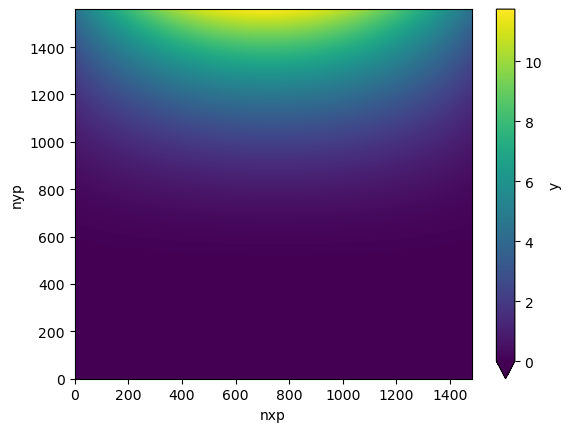

In [64]:
t_angles.plot(vmin=0)

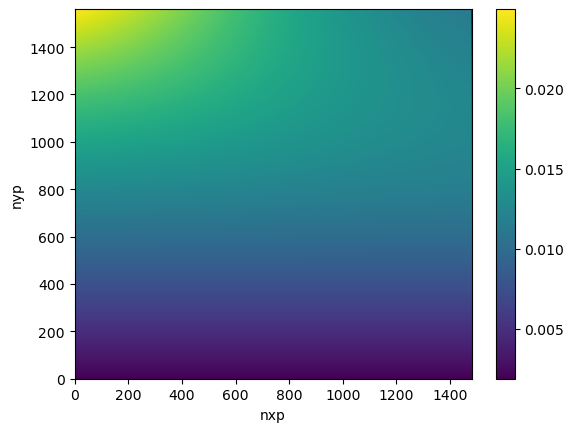

In [66]:
(hgrid["angle_dx"]-t_angles).plot()